# ANGANI AIR: TURNING LOYALTY DATA INTO CUSTOMER GROWTH
## The Business Situation
#### Angani Air (AA) is a growing African airline competing in an increasingly competitive travel market. To strengthen customer loyalty and encourage repeat travel, AA launched a Loyalty Program Promotion between February and April 2018. 
#### The campaign generated a significant number of new loyalty-program signups. However, senior management now faces a more important question: “Did the 2018 Loyalty Program Promotion create valuable customer behaviour, and how should Angani Air improve its loyalty strategy?”. 
#### Management wants to understand:
#### 1. Whether the campaign changed customer behaviour
#### 2. Where AA should focus its future loyalty investment

In [123]:
# import the data analysis libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

In [124]:
# create dataframes
#airline_loyalty = pd.read_csv('/home/r0b0t/Videos/KeDataLab/Python For Data Analytics/Week 3/Project/data/Airline Loyalty Data Dictionary.csv')
calendar = pd.read_csv('/home/r0b0t/Videos/KeDataLab/Python For Data Analytics/Week 3/Project/data/Calendar.csv')
flight_activity = pd.read_csv('/home/r0b0t/Videos/KeDataLab/Python For Data Analytics/Week 3/Project/data/Customer Flight Activity.csv')
customer_loyalty = pd.read_csv('/home/r0b0t/Videos/KeDataLab/Python For Data Analytics/Week 3/Project/data/Customer Loyalty History.csv')

In [125]:
# preview our data
summary_df = pd.DataFrame({
    'Dataset': ['Calendar', 'Customer Flight Activity', 'Customer Loyalty History'],
    'Rows': [len(calendar), len(flight_activity), len(customer_loyalty)],
    'Columns': [calendar.shape[1], flight_activity.shape[1], customer_loyalty.shape[1]]
})

display(summary_df)

display(calendar.head())
display(flight_activity.head())
display(customer_loyalty.head())

,Dataset,Rows,Columns
0,Calendar,2557,4
1,Customer Flight Activity,392936,8
2,Customer Loyalty History,16737,16


,Date,Start of Year,Start of Quarter,Start of Month
0,2012-01-01,2012-01-01,2012-01-01,2012-01-01
1,2012-01-02,2012-01-01,2012-01-01,2012-01-01
2,2012-01-03,2012-01-01,2012-01-01,2012-01-01
3,2012-01-04,2012-01-01,2012-01-01,2012-01-01
4,2012-01-05,2012-01-01,2012-01-01,2012-01-01


,Loyalty Number,Year,Month,Total Flights,Distance,Points Accumulated,Points Redeemed,Dollar Cost Points Redeemed
0,100590,2018,6,12,15276,22914.0,0,0
1,100590,2018,7,12,9168,13752.0,0,0
2,100590,2018,5,4,6504,9756.0,0,0
3,100590,2018,10,0,0,0.0,512,92
4,100590,2018,2,0,0,0.0,0,0


,Loyalty Number,Country,Province,City,Postal Code,Gender,Education,Salary,Marital Status,Loyalty Card,CLV,Enrollment Type,Enrollment Year,Enrollment Month,Cancellation Year,Cancellation Month
0,480934,Canada,Ontario,Toronto,M2Z 4K1,Female,Bachelor,83236.0,Married,Star,3839.14,Standard,2016,2,NaN,NaN
1,549612,Canada,Alberta,Edmonton,T3G 6Y6,Male,College,NaN,Divorced,Star,3839.61,Standard,2016,3,NaN,NaN
2,429460,Canada,British Columbia,Vancouver,V6E 3D9,Male,College,NaN,Single,Star,3839.75,Standard,2014,7,2018.0,1.0
3,608370,Canada,Ontario,Toronto,P1W 1K4,Male,College,NaN,Single,Star,3839.75,Standard,2013,2,NaN,NaN
4,530508,Canada,Quebec,Hull,J8Y 3Z5,Male,Bachelor,103495.0,Married,Star,3842.79,Standard,2014,10,NaN,NaN


In [126]:
# data quality audit

def quality_audit(df, name):
    print(f'--- Data quality audit for {name} ---')
    audit = pd.DataFrame({
        'Missing Values': df.isna().sum(),
        'Missing Values (%)': (df.isnull().sum()/len(df)) * 100,
        'Data Types': df.dtypes,
        'Unique Values': df.nunique()
    })
    display(audit) #[audit['Missing Values']].sort_values(by='Missing Values', ascending=False))
    print(f'Duplicate Rows: {df.duplicated().sum()}')

quality_audit(calendar, 'Calendar')
quality_audit(flight_activity, 'Customer Flight Activity')
quality_audit(customer_loyalty, 'Customer Loyalty History')

--- Data quality audit for Calendar ---


,Missing Values,Missing Values (%),Data Types,Unique Values
Date,0,0.0,str,2557
Start of Year,0,0.0,str,7
Start of Quarter,0,0.0,str,28
Start of Month,0,0.0,str,84


Duplicate Rows: 0
--- Data quality audit for Customer Flight Activity ---


,Missing Values,Missing Values (%),Data Types,Unique Values
Loyalty Number,0,0.0,int64,16737
Year,0,0.0,int64,2
Month,0,0.0,int64,12
Total Flights,0,0.0,int64,17
Distance,0,0.0,int64,9456
Points Accumulated,0,0.0,float64,10284
Points Redeemed,0,0.0,int64,587
Dollar Cost Points Redeemed,0,0.0,int64,108


Duplicate Rows: 1922
--- Data quality audit for Customer Loyalty History ---


,Missing Values,Missing Values (%),Data Types,Unique Values
Loyalty Number,0,0.000000,int64,16737
Country,0,0.000000,str,1
Province,0,0.000000,str,11
City,0,0.000000,str,29
Postal Code,0,0.000000,str,55
Gender,0,0.000000,str,2
Education,0,0.000000,str,5
Salary,4238,25.321145,float64,5890
Marital Status,0,0.000000,str,3
Loyalty Card,0,0.000000,str,3


Duplicate Rows: 0


### Data Cleaning

In [127]:
# for calendar df, convert date column to datetime format
calendar['Date'] = pd.to_datetime(calendar['Date'], format='%Y-%m-%d')

In [128]:
customer_loyalty.head(10)

,Loyalty Number,Country,Province,City,Postal Code,Gender,Education,Salary,Marital Status,Loyalty Card,CLV,Enrollment Type,Enrollment Year,Enrollment Month,Cancellation Year,Cancellation Month
0,480934,Canada,Ontario,Toronto,M2Z 4K1,Female,Bachelor,83236.0,Married,Star,3839.14,Standard,2016,2,NaN,NaN
1,549612,Canada,Alberta,Edmonton,T3G 6Y6,Male,College,NaN,Divorced,Star,3839.61,Standard,2016,3,NaN,NaN
2,429460,Canada,British Columbia,Vancouver,V6E 3D9,Male,College,NaN,Single,Star,3839.75,Standard,2014,7,2018.0,1.0
3,608370,Canada,Ontario,Toronto,P1W 1K4,Male,College,NaN,Single,Star,3839.75,Standard,2013,2,NaN,NaN
4,530508,Canada,Quebec,Hull,J8Y 3Z5,Male,Bachelor,103495.0,Married,Star,3842.79,Standard,2014,10,NaN,NaN
5,193662,Canada,Yukon,Whitehorse,Y2K 6R0,Male,Bachelor,51124.0,Married,Star,3844.57,Standard,2012,5,NaN,NaN
6,927943,Canada,Ontario,Toronto,P5S 6R4,Female,College,NaN,Single,Star,3857.95,Standard,2014,6,NaN,NaN
7,188893,Canada,Ontario,Trenton,K8V 4B2,Male,Bachelor,100159.0,Married,Star,3861.49,Standard,2016,12,NaN,NaN
8,852392,Canada,Quebec,Montreal,H2Y 2W2,Female,Bachelor,100159.0,Married,Star,3861.49,Standard,2015,5,NaN,NaN
9,866307,Canada,Ontario,Toronto,M8Y 4K8,Male,Bachelor,100159.0,Married,Star,3861.49,Standard,2016,10,NaN,NaN


In [129]:
# fill missing values in the 'Customer Loyalty History' dataset with 0
customer_loyalty_cols = ['Salary', 'Cancellation Year', 'Cancellation Month']
for col in customer_loyalty_cols:
    customer_loyalty[col] = customer_loyalty[col].fillna(0)
    #why not fillna with mean or median? Because these columns are categorical and not continuous, so filling with 0 is more appropriate.
    #why not fillnull()

In [130]:
customer_loyalty.info()

<class 'pandas.DataFrame'>
RangeIndex: 16737 entries, 0 to 16736
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Loyalty Number      16737 non-null  int64  
 1   Country             16737 non-null  str    
 2   Province            16737 non-null  str    
 3   City                16737 non-null  str    
 4   Postal Code         16737 non-null  str    
 5   Gender              16737 non-null  str    
 6   Education           16737 non-null  str    
 7   Salary              16737 non-null  float64
 8   Marital Status      16737 non-null  str    
 9   Loyalty Card        16737 non-null  str    
 10  CLV                 16737 non-null  float64
 11  Enrollment Type     16737 non-null  str    
 12  Enrollment Year     16737 non-null  int64  
 13  Enrollment Month    16737 non-null  int64  
 14  Cancellation Year   16737 non-null  float64
 15  Cancellation Month  16737 non-null  float64
dtypes: float64(4), 

### Merge customer and flight data

In [131]:
# record number of rows before merge
len(customer_loyalty)

16737

In [132]:
len(flight_activity)

392936

In [133]:
# customer_loyalty is our main df
df = customer_loyalty.merge(flight_activity, on='Loyalty Number', how='left')

In [134]:
len(df)

392936

In [135]:
df.head()

,Loyalty Number,Country,Province,City,Postal Code,Gender,Education,Salary,Marital Status,Loyalty Card,...,Enrollment Month,Cancellation Year,Cancellation Month,Year,Month,Total Flights,Distance,Points Accumulated,Points Redeemed,Dollar Cost Points Redeemed
0,480934,Canada,Ontario,Toronto,M2Z 4K1,Female,Bachelor,83236.0,Married,Star,...,2,0.0,0.0,2018,7,5,11355,11355.0,0,0
1,480934,Canada,Ontario,Toronto,M2Z 4K1,Female,Bachelor,83236.0,Married,Star,...,2,0.0,0.0,2017,5,4,4908,4908.0,0,0
2,480934,Canada,Ontario,Toronto,M2Z 4K1,Female,Bachelor,83236.0,Married,Star,...,2,0.0,0.0,2017,6,4,6948,6948.0,0,0
3,480934,Canada,Ontario,Toronto,M2Z 4K1,Female,Bachelor,83236.0,Married,Star,...,2,0.0,0.0,2017,8,4,5516,5516.0,0,0
4,480934,Canada,Ontario,Toronto,M2Z 4K1,Female,Bachelor,83236.0,Married,Star,...,2,0.0,0.0,2018,4,4,4376,4376.0,0,0


In [136]:
# data audit after merge
def quality_audit(df, name):
    print(f'--- Data quality audit for {name} ---')
    audit = pd.DataFrame({
        'Missing Values': df.isna().sum(),
        'Missing Values (%)': (df.isnull().sum()/len(df)) * 100,
        'Data Types': df.dtypes,
        'Unique Values': df.nunique()
    })
    display(audit) #[audit['Missing Values']].sort_values(by='Missing Values', ascending=False))
    print(f'Duplicate Rows: {df.duplicated().sum()}')

quality_audit(df, 'Merged Customer Loyalty and Flight Activity')

--- Data quality audit for Merged Customer Loyalty and Flight Activity ---


,Missing Values,Missing Values (%),Data Types,Unique Values
Loyalty Number,0,0.0,int64,16737
Country,0,0.0,str,1
Province,0,0.0,str,11
City,0,0.0,str,29
Postal Code,0,0.0,str,55
Gender,0,0.0,str,2
Education,0,0.0,str,5
Salary,0,0.0,float64,5891
Marital Status,0,0.0,str,3
Loyalty Card,0,0.0,str,3


Duplicate Rows: 1922


In [137]:
df['Year']

0         2018
1         2017
2         2017
3         2017
4         2018
          ... 
392931    2018
392932    2018
392933    2018
392934    2018
392935    2018
Name: Year, Length: 392936, dtype: int64

In [138]:
# check for unmatched flight data
print(f'Unmatched flights: {df['Total Flights'].isna().sum()}')

Unmatched flights: 0


### Feature Engineering

In [139]:
calendar.head(10)

,Date,Start of Year,Start of Quarter,Start of Month
0,2012-01-01,2012-01-01,2012-01-01,2012-01-01
1,2012-01-02,2012-01-01,2012-01-01,2012-01-01
2,2012-01-03,2012-01-01,2012-01-01,2012-01-01
3,2012-01-04,2012-01-01,2012-01-01,2012-01-01
4,2012-01-05,2012-01-01,2012-01-01,2012-01-01
5,2012-01-06,2012-01-01,2012-01-01,2012-01-01
6,2012-01-07,2012-01-01,2012-01-01,2012-01-01
7,2012-01-08,2012-01-01,2012-01-01,2012-01-01
8,2012-01-09,2012-01-01,2012-01-01,2012-01-01
9,2012-01-10,2012-01-01,2012-01-01,2012-01-01


In [140]:
# monthly date column
df['ActivityDate'] = pd.to_datetime(
    dict(year=df['Year'], month=df['Month'], day=1)
)

In [141]:
# calendar features
df['Quarter'] = df['ActivityDate'].dt.quarter
df['MonthName'] = df['ActivityDate'].dt.month_name()
df['YearMonth'] = df['ActivityDate'].dt.to_period('M')

In [142]:
df.head()

,Loyalty Number,Country,Province,City,Postal Code,Gender,Education,Salary,Marital Status,Loyalty Card,...,Month,Total Flights,Distance,Points Accumulated,Points Redeemed,Dollar Cost Points Redeemed,ActivityDate,Quarter,MonthName,YearMonth
0,480934,Canada,Ontario,Toronto,M2Z 4K1,Female,Bachelor,83236.0,Married,Star,...,7,5,11355,11355.0,0,0,2018-07-01,3,July,2018-07
1,480934,Canada,Ontario,Toronto,M2Z 4K1,Female,Bachelor,83236.0,Married,Star,...,5,4,4908,4908.0,0,0,2017-05-01,2,May,2017-05
2,480934,Canada,Ontario,Toronto,M2Z 4K1,Female,Bachelor,83236.0,Married,Star,...,6,4,6948,6948.0,0,0,2017-06-01,2,June,2017-06
3,480934,Canada,Ontario,Toronto,M2Z 4K1,Female,Bachelor,83236.0,Married,Star,...,8,4,5516,5516.0,0,0,2017-08-01,3,August,2017-08
4,480934,Canada,Ontario,Toronto,M2Z 4K1,Female,Bachelor,83236.0,Married,Star,...,4,4,4376,4376.0,0,0,2018-04-01,2,April,2018-04


In [143]:
# seasonal grouping
df['Season'] = df['Month'].map({
    12:'Winter', 1:'Winter', 2:'Winter',
    3:'Spring', 4:'Spring', 5:'Spring',
    6:'Summer', 7:'Summer', 8:'Summer',
    9:'Fall', 10:'Fall', 11:'Fall'
})

In [144]:
# cyclical monthly features useful for modeling seasonality
df['MonthSin'] = np.sin(2*np.pi*df['Month']/12)
df['MonthCos'] = np.cos(2*np.pi*df['Month']/12)

In [145]:
df.head()

,Loyalty Number,Country,Province,City,Postal Code,Gender,Education,Salary,Marital Status,Loyalty Card,...,Points Accumulated,Points Redeemed,Dollar Cost Points Redeemed,ActivityDate,Quarter,MonthName,YearMonth,Season,MonthSin,MonthCos
0,480934,Canada,Ontario,Toronto,M2Z 4K1,Female,Bachelor,83236.0,Married,Star,...,11355.0,0,0,2018-07-01,3,July,2018-07,Summer,-5.000000e-01,-0.866025
1,480934,Canada,Ontario,Toronto,M2Z 4K1,Female,Bachelor,83236.0,Married,Star,...,4908.0,0,0,2017-05-01,2,May,2017-05,Spring,5.000000e-01,-0.866025
2,480934,Canada,Ontario,Toronto,M2Z 4K1,Female,Bachelor,83236.0,Married,Star,...,6948.0,0,0,2017-06-01,2,June,2017-06,Summer,1.224647e-16,-1.000000
3,480934,Canada,Ontario,Toronto,M2Z 4K1,Female,Bachelor,83236.0,Married,Star,...,5516.0,0,0,2017-08-01,3,August,2017-08,Summer,-8.660254e-01,-0.500000
4,480934,Canada,Ontario,Toronto,M2Z 4K1,Female,Bachelor,83236.0,Married,Star,...,4376.0,0,0,2018-04-01,2,April,2018-04,Spring,8.660254e-01,-0.500000


In [146]:
df[df.duplicated]

,Loyalty Number,Country,Province,City,Postal Code,Gender,Education,Salary,Marital Status,Loyalty Card,...,Points Accumulated,Points Redeemed,Dollar Cost Points Redeemed,ActivityDate,Quarter,MonthName,YearMonth,Season,MonthSin,MonthCos
151,193662,Canada,Yukon,Whitehorse,Y2K 6R0,Male,Bachelor,51124.0,Married,Star,...,0.0,0,0,2017-01-01,1,January,2017-01,Winter,5.000000e-01,0.866025
156,193662,Canada,Yukon,Whitehorse,Y2K 6R0,Male,Bachelor,51124.0,Married,Star,...,0.0,0,0,2018-01-01,1,January,2018-01,Winter,5.000000e-01,0.866025
162,193662,Canada,Yukon,Whitehorse,Y2K 6R0,Male,Bachelor,51124.0,Married,Star,...,0.0,0,0,2018-08-01,3,August,2018-08,Summer,-8.660254e-01,-0.500000
166,193662,Canada,Yukon,Whitehorse,Y2K 6R0,Male,Bachelor,51124.0,Married,Star,...,0.0,0,0,2018-11-01,4,November,2018-11,Fall,-5.000000e-01,0.866025
2875,746226,Canada,British Columbia,Whistler,V6T 1Y8,Female,Bachelor,63501.0,Married,Star,...,0.0,0,0,2017-01-01,1,January,2017-01,Winter,5.000000e-01,0.866025
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
369741,373638,Canada,Ontario,Thunder Bay,K8T 5M5,Female,Bachelor,92501.0,Divorced,Star,...,0.0,0,0,2018-04-01,2,April,2018-04,Spring,8.660254e-01,-0.500000
369743,373638,Canada,Ontario,Thunder Bay,K8T 5M5,Female,Bachelor,92501.0,Divorced,Star,...,0.0,0,0,2018-05-01,2,May,2018-05,Spring,5.000000e-01,-0.866025
369745,373638,Canada,Ontario,Thunder Bay,K8T 5M5,Female,Bachelor,92501.0,Divorced,Star,...,0.0,0,0,2018-06-01,2,June,2018-06,Summer,1.224647e-16,-1.000000
369747,373638,Canada,Ontario,Thunder Bay,K8T 5M5,Female,Bachelor,92501.0,Divorced,Star,...,0.0,0,0,2018-07-01,3,July,2018-07,Summer,-5.000000e-01,-0.866025


In [147]:
df.shape

(392936, 30)

##### Travel behavior per customer features

In [148]:
# aggregate activity rows to one row per customer per month
monthly_travel = (df.groupby(['Loyalty Number', 'Year', 'Month'], as_index=False)
                  .agg(
                      TotalFlights=('Total Flights', 'sum'),
                      TotalDistance=('Distance', 'sum')
                  ))

In [149]:
# mark months with and without flights
monthly_travel['ActiveMonth'] = monthly_travel['TotalFlights']>0
monthly_travel['InactiveMonth'] = monthly_travel['TotalFlights']==0

In [150]:
monthly_travel.head(10)

,Loyalty Number,Year,Month,TotalFlights,TotalDistance,ActiveMonth,InactiveMonth
0,100018,2017,1,1,601,True,False
1,100018,2017,2,0,0,False,True
2,100018,2017,3,4,9648,True,False
3,100018,2017,4,1,1654,True,False
4,100018,2017,5,0,0,False,True
5,100018,2017,6,1,2489,True,False
6,100018,2017,7,3,3687,True,False
7,100018,2017,8,3,7116,True,False
8,100018,2017,9,3,5751,True,False
9,100018,2017,10,2,3728,True,False


In [151]:
# summarize travel behavior for each customer
customer_travel = (
    monthly_travel.groupby('Loyalty Number')
    .agg(
        TotalFlights=('TotalFlights', 'sum'),
        TotalDistance=('TotalDistance', 'sum'),
        ActiveMonths=('ActiveMonth', 'sum'),
        MonthsObserved=('Month', 'size'),
        NoFlightMonthRate=('InactiveMonth', 'mean'),
        AvgFlightsPerMonth=('TotalFlights', 'mean'),
        AvgFlightsPerActiveMonth=('TotalFlights', lambda values: values[values>0].mean())
    )
    .reset_index()
)

In [152]:
# average distance per flight
customer_travel['AvgDistancePerFlight'] = (
    customer_travel['TotalDistance'] / 
customer_travel['TotalFlights'].replace(0, np.nan)
)

In [153]:
customer_travel.head()

,Loyalty Number,TotalFlights,TotalDistance,ActiveMonths,MonthsObserved,NoFlightMonthRate,AvgFlightsPerMonth,AvgFlightsPerActiveMonth,AvgDistancePerFlight
0,100018,46,81190,18,24,0.250000,1.916667,2.555556,1765.000000
1,100102,51,68918,17,24,0.291667,2.125000,3.000000,1351.333333
2,100140,47,72856,17,24,0.291667,1.958333,2.764706,1550.127660
3,100214,22,38236,9,24,0.625000,0.916667,2.444444,1738.000000
4,100272,37,54997,13,24,0.458333,1.541667,2.846154,1486.405405


##### Loyalty engagement features

In [154]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 392936 entries, 0 to 392935
Data columns (total 30 columns):
 #   Column                       Non-Null Count   Dtype         
---  ------                       --------------   -----         
 0   Loyalty Number               392936 non-null  int64         
 1   Country                      392936 non-null  str           
 2   Province                     392936 non-null  str           
 3   City                         392936 non-null  str           
 4   Postal Code                  392936 non-null  str           
 5   Gender                       392936 non-null  str           
 6   Education                    392936 non-null  str           
 7   Salary                       392936 non-null  float64       
 8   Marital Status               392936 non-null  str           
 9   Loyalty Card                 392936 non-null  str           
 10  CLV                          392936 non-null  float64       
 11  Enrollment Type              392936 n

In [155]:
# combine activity rows within each customer-month
monthly_engagement = (
    df.groupby(['Loyalty Number', 'Year', 'Month'], as_index=False)
    .agg(
        PointsAccumulated=('Points Accumulated', 'sum'),
        PointsRedeemed=('Points Redeemed', 'sum'),
        RedemptionCost=('Dollar Cost Points Redeemed', 'sum'),
        TotalFlights=('Total Flights', 'sum')
    )
)

In [156]:
# create customer-level engagement features
loyalty_engagement = (
    monthly_engagement.groupby('Loyalty Number')
    .agg(
        TotalPointsAccumulated=('PointsAccumulated', 'sum'),
        TotalPointsRedeemed=('PointsRedeemed', 'sum'),
        TotalRedemptionCost=('RedemptionCost', 'sum'),
        TotalFlights=('TotalFlights', 'sum'),
        MonthsWithRedemptions=('PointsRedeemed', lambda values:(values>0).sum())
    )
    .reset_index()
)

In [157]:
# redemption rate
loyalty_engagement['PointsRedemptionRate'] = (
    loyalty_engagement['TotalPointsRedeemed'] / 
    loyalty_engagement['TotalPointsAccumulated'].replace(0, np.nan)
)

In [158]:
# average points accumulated per flight
loyalty_engagement['PointsPerFlight'] = (
    loyalty_engagement['TotalPointsAccumulated'] / 
    loyalty_engagement['TotalFlights'].replace(0, np.nan)
)

In [159]:
# average cost per redeemed point
loyalty_engagement['CostPerPointRedeemed'] = (
    loyalty_engagement['TotalRedemptionCost'] /
    loyalty_engagement['TotalPointsRedeemed'].replace(0, np.nan)
)

##### Activity timing features

In [160]:
# aggregate activity rows to one row per customer per month
monthly_activity_timing = (
    df.groupby(['Loyalty Number', 'Year', 'Month'], as_index=False)
    .agg(TotalFlights=('Total Flights', 'sum'))
)

In [161]:
# create a monthly date and identify each customer's last active month
monthly_activity_timing['ActivityDate'] = pd.to_datetime(
    dict(
        year=monthly_activity_timing['Year'],
        month=monthly_activity_timing['Month'],
        day=1 
    )
)

last_active = (
    monthly_activity_timing.loc[monthly_activity_timing['TotalFlights']>0]
    .groupby('Loyalty Number', as_index=False)
    .agg(LastActiveDate=('ActivityDate', 'max'))
)

In [162]:
# keep customers who had no active month in the results too
customer_activity_timing = (
    df[['Loyalty Number']]
    .drop_duplicates()
    .merge(last_active, on='Loyalty Number', how='left')
)

In [163]:
monthly_activity_timing.info()

<class 'pandas.DataFrame'>
RangeIndex: 389065 entries, 0 to 389064
Data columns (total 5 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   Loyalty Number  389065 non-null  int64         
 1   Year            389065 non-null  int64         
 2   Month           389065 non-null  int64         
 3   TotalFlights    389065 non-null  int64         
 4   ActivityDate    389065 non-null  datetime64[us]
dtypes: datetime64[us](1), int64(4)
memory usage: 14.8 MB


In [164]:
# months since last flight, relative to the dataset's final activity month
observation_date = monthly_activity_timing['ActivityDate'].max()
customer_activity_timing['MonthsSinceLastFlight'] = (
    (observation_date.year * 12 + observation_date.month)
    - (
        customer_activity_timing['LastActiveDate'].dt.year * 12 +
        customer_activity_timing['LastActiveDate'].dt.month
    )
)

In [165]:
# compare each customer's total flights in 2017 and 2018
yearly_flights = (
    monthly_activity_timing.pivot_table(
        index='Loyalty Number',
        columns='Year',
        values='TotalFlights',
        aggfunc='sum',
        fill_value=0
    )
    .reindex(columns=[2017, 2018], fill_value=0)
)

yearly_flights.columns = ['Flights2017', 'Flights2018']
yearly_flights['FlightChange2018Vs2017'] = (
    yearly_flights['Flights2018'] - yearly_flights['Flights2017']
)

In [166]:
# percentage change
yearly_flights['FlightPercentChange2018Vs2017'] = (
    yearly_flights['FlightChange2018Vs2017'].
    div(yearly_flights['Flights2017']).replace(0, np.nan)*100
)

In [167]:
yearly_flights.head()

,Flights2017,Flights2018,FlightChange2018Vs2017,FlightPercentChange2018Vs2017
Loyalty Number,,,,
100018,24,22,-2,-8.333333
100102,25,26,1,4.000000
100140,22,25,3,13.636364
100214,10,12,2,20.000000
100272,20,17,-3,-15.000000


In [168]:
# add yearly comparison features to timing features
customer_activity_timing = customer_activity_timing.merge(
    yearly_flights.reset_index(),
    on='Loyalty Number',
    how='left'
)

##### Membership lifecycle

In [169]:
# copy customer loyalty
membership_life = customer_loyalty.copy()

In [170]:
membership_life.info()

<class 'pandas.DataFrame'>
RangeIndex: 16737 entries, 0 to 16736
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Loyalty Number      16737 non-null  int64  
 1   Country             16737 non-null  str    
 2   Province            16737 non-null  str    
 3   City                16737 non-null  str    
 4   Postal Code         16737 non-null  str    
 5   Gender              16737 non-null  str    
 6   Education           16737 non-null  str    
 7   Salary              16737 non-null  float64
 8   Marital Status      16737 non-null  str    
 9   Loyalty Card        16737 non-null  str    
 10  CLV                 16737 non-null  float64
 11  Enrollment Type     16737 non-null  str    
 12  Enrollment Year     16737 non-null  int64  
 13  Enrollment Month    16737 non-null  int64  
 14  Cancellation Year   16737 non-null  float64
 15  Cancellation Month  16737 non-null  float64
dtypes: float64(4), 

In [171]:
# build enrollment dates
membership_life['EnrollmentDate'] = pd.to_datetime(
    dict(
        year=membership_life['Enrollment Year'],
        month=membership_life['Enrollment Month'],
        day=1
    )
)

In [172]:
# build cancellation dates
cancel_year = membership_life['Cancellation Year'].where(
    membership_life['Cancellation Year'] != 0
)
cancel_month = membership_life['Cancellation Month'].where(
    membership_life['Cancellation Month'] != 0
)
membership_life['CancellationDate'] = pd.to_datetime(
    dict(
        year=cancel_year,
        month=cancel_month,
        day=1
    ),
    errors='coerce'
)

In [173]:
# use last month in activity data as observation cutoff
observation_date = pd.to_datetime(
    dict(
        year=flight_activity['Year'],
        month=flight_activity['Month'],
        day=1
    )
).max()

In [174]:
#flag cancellations recorded by observation cutoff
membership_life['IsCancelled'] = (
    membership_life['CancellationDate'].notna() &
    (membership_life['CancellationDate']<=observation_date)
)
membership_life['IsActiveAtCutoff'] = ~membership_life['IsCancelled']

In [175]:
# memebrship tenure
membership_life['MembershipEndDate'] = (
    membership_life['CancellationDate'].
    where(membership_life['IsCancelled'], observation_date)
)

In [176]:
# calculate elapsed membership duration in months
membership_life['MembershipTenureMonths'] = (
    membership_life['MembershipEndDate'].dt.year*12 +
    membership_life['MembershipEndDate'].dt.month -
    membership_life['EnrollmentDate'].dt.year*12 -
    membership_life['EnrollmentDate'].dt.month
)

In [177]:
# enrollment cohort and promotion indicator
membership_life['EnrollmentCohort'] = (
    membership_life['EnrollmentDate'].dt.to_period('M')
)
membership_life['EnrollmentQuarter'] = (
    membership_life['EnrollmentDate'].dt.quarter
)
membership_life['IsPromotionEnrollment'] = (
    membership_life['Enrollment Type'] == '2018 Promotion'
)

In [178]:
# Count enrollment types by year
pd.crosstab(
    customer_loyalty['Enrollment Year'],
    customer_loyalty['Enrollment Type']
)

Enrollment Type,2018 Promotion,Standard
Enrollment Year,,
2012,0,1686
2013,0,2397
2014,0,2370
2015,0,2331
2016,0,2456
2017,0,2487
2018,971,2039


##### Customer profile features

In [179]:
customer_profile = customer_loyalty.copy()

In [180]:
# restore missing salaries as NaN and record
customer_profile['Salary'] = customer_profile['Salary'].replace(0, np.nan)
customer_profile['SalaryMissing'] = customer_profile['Salary'].isna()

In [181]:
customer_profile.info()

<class 'pandas.DataFrame'>
RangeIndex: 16737 entries, 0 to 16736
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Loyalty Number      16737 non-null  int64  
 1   Country             16737 non-null  str    
 2   Province            16737 non-null  str    
 3   City                16737 non-null  str    
 4   Postal Code         16737 non-null  str    
 5   Gender              16737 non-null  str    
 6   Education           16737 non-null  str    
 7   Salary              12499 non-null  float64
 8   Marital Status      16737 non-null  str    
 9   Loyalty Card        16737 non-null  str    
 10  CLV                 16737 non-null  float64
 11  Enrollment Type     16737 non-null  str    
 12  Enrollment Year     16737 non-null  int64  
 13  Enrollment Month    16737 non-null  int64  
 14  Cancellation Year   16737 non-null  float64
 15  Cancellation Month  16737 non-null  float64
 16  SalaryMissing  

In [182]:
# salary band
customer_profile['SalaryBand'] = pd.qcut(
    customer_profile['Salary'],
    q=4,
    labels=['Lower', 'Lower-middle', 'Upper-middle', 'Higher']
)

In [183]:
# divide customer lifetime value into 4 groups
customer_profile['CLVSegment'] = pd.qcut(
    customer_profile['CLV'],
    q=4,
    labels=['Lower', 'Lower-middle', 'Upper-middle', 'Higher']
)

In [184]:
# represent the ordered loyalty-card tiers numerically
customer_profile['LoyaltyCardLevel'] = (
    customer_profile['Loyalty Card']
    .map({'Aurora':1, 'Nova':2, 'Star':3})
)

In [185]:
# represent education as ordered feature
customer_profile['EducationLevel'] = (
    customer_profile['Education']
    .map({
        'High School or Below':1,
        'College':2,
        'Bachelor':3,
        'Master':4,
        'Doctor':5
    })
)

In [186]:
# one-hot encode low-cardinality profile fields
#customer_profile = pd.get_dummies(
 #   customer_profile,
  #  columns=['Gender', 'Marital Status', 'Province'],
   # dtype=int
#)

##### Campaign comparison features

In [187]:
# select promotion members and same-month standard members
campaign_cohort = customer_loyalty[
    customer_loyalty['Enrollment Year'].eq(2018)
    & customer_loyalty['Enrollment Month'].between(2,4)
    & customer_loyalty['Enrollment Type'].isin(['2018 Promotion', 'Standard'])
][
    ['Loyalty Number', 'Enrollment Type', 'Enrollment Month']
].copy()

In [188]:
# aggregate activity rows to one row per customer per month
monthly_campaign_activity = (
    flight_activity
    .groupby(['Loyalty Number', 'Year', 'Month'], as_index=False)
    .agg(
        TotalFlights=('Total Flights', 'sum'),
        Distance=('Distance', 'sum'),
        PointsAccumulated=('Points Accumulated', 'sum'),
        PointsRedeemed=('Points Redeemed', 'sum')
    )
)

In [189]:
# Create three comparable months of follow-up for each customer:
# enrollment month and the next two months
campaign_window = campaign_cohort.merge(
    pd.DataFrame({'MonthsAfterEnrollment': [0,1,2]}),
    how='cross'
)

In [190]:
# convert enrollment month plus offset to activity year/month
campaign_window['ActivityMonthIndex'] = (
    2018*12 + 
    campaign_window['Enrollment Month'] - 1
    + campaign_window['MonthsAfterEnrollment']
)
campaign_window['Year'] = campaign_window['ActivityMonthIndex'] // 12
campaign_window['Month'] = campaign_window['ActivityMonthIndex'] % 12+1

In [191]:
# combine activity aggregated to customer-month level
campaign_window = campaign_window.merge(
    monthly_campaign_activity,
    on=['Loyalty Number', 'Year', 'Month'],
    how='left',
    validate='one_to_one'
)

In [192]:
# Treat missing activity records in this three-month window as zero activity
activity_columns = [
    'TotalFlights',
    'Distance',
    'PointsAccumulated',
    'PointsRedeemed'
]
campaign_window[activity_columns] = campaign_window[activity_columns].fillna(0)

In [193]:
#create 1 row per customer with 3 outcomes
customer_campaign_3m = (
    campaign_window
    .groupby(
        ['Loyalty Number', 'Enrollment Type', 'Enrollment Month'],
        as_index=False
    )
    .agg(
        Flights3Months=('TotalFlights', 'sum'),
        Distance3Months=('Distance', 'sum'),
        PointsAccumulated3Months=('PointsAccumulated', 'sum'),
        PointsRedeemed3Months=('PointsRedeemed', 'sum'),
        ActiveMonths3=('TotalFlights', lambda values: (values > 0).sum())
    )
)

customer_campaign_3m['HadAnyFlight3Months'] = (
    customer_campaign_3m['Flights3Months'] > 0
)
customer_campaign_3m['ActiveMonthRate3'] = (
    customer_campaign_3m['ActiveMonths3'] / 3
)

In [194]:
# summarize outcomes by promotion type and enrollment month
campaign_summary_3m = (
    customer_campaign_3m
    .groupby(['Enrollment Month', 'Enrollment Type'], as_index=False)
    .agg(
        Customers=('Loyalty Number', 'nunique'),
        AvgFlights3Months=('Flights3Months', 'mean'),
        MedianFlights3Months=('Flights3Months', 'median'),
        AnyFlightRate=('HadAnyFlight3Months', 'mean'),
        AvgActiveMonthRate=('ActiveMonthRate3', 'mean'),
        AvgDistance3Months=('Distance3Months', 'mean'),
        AvgPointsAccumulated3Months=('PointsAccumulated3Months', 'mean'),
        AvgPointsRedeemed3Months=('PointsRedeemed3Months', 'mean')
    )
)

campaign_summary_3m['AnyFlightPercent'] = (
    campaign_summary_3m['AnyFlightRate'] * 100
)

In [195]:
# keep only activity from enrollment month through Dec 2018
post_enrollment_activity = monthly_campaign_activity.merge(
    campaign_cohort, on='Loyalty Number', how='inner'
)

post_enrollment_activity = post_enrollment_activity[
    post_enrollment_activity['Year'].eq(2018) &(
        post_enrollment_activity['Month']
        >= post_enrollment_activity['Enrollment Month']
    )
]

In [196]:
# summarize each customer's activity after enrollment
customer_campaign_outcomes = (
    post_enrollment_activity
    .groupby('Loyalty Number', as_index=False)
    .agg(
        PostEnrollmentFlights=('TotalFlights', 'sum'),
        PostEnrollmentDistance=('Distance', 'sum'),
        PostEnrollmentPointsAccumulated=('PointsAccumulated', 'sum'),
        PostEnrollmentPointsRedeemed=('PointsRedeemed', 'sum'),
        ActiveMonths=(
            'TotalFlights',
            lambda values:(values > 0).sum()
        )
    )
)

In [197]:
# keep cohort members even if no post_enrollment activity rows matched
customer_campaign_outcomes = campaign_cohort.merge(
    customer_campaign_outcomes, on='Loyalty Number',
    how='left'
)
outcome_columns = [
    'PostEnrollmentFlights',
    'PostEnrollmentDistance',
    'PostEnrollmentPointsAccumulated',
    'PostEnrollmentPointsRedeemed',
    'ActiveMonths'
]

customer_campaign_outcomes[outcome_columns] = (
    customer_campaign_outcomes[outcome_columns].fillna(0)
)

In [198]:
# account for different observation windows: Feb enrollees have more
# observed months than April enrollees
customer_campaign_outcomes['MonthsObserved'] = (
    13 - customer_campaign_outcomes['Enrollment Month']
)
customer_campaign_outcomes['FlightsPerObservedMonth'] = (
    customer_campaign_outcomes['PostEnrollmentFlights'] /
    customer_campaign_outcomes['MonthsObserved']
)
customer_campaign_outcomes['DistancePerObservedMonth'] = (
    customer_campaign_outcomes['PostEnrollmentDistance'] /
    customer_campaign_outcomes['MonthsObserved']
)

In [199]:
# compare promotion and standard members within each enrollment month
campaign_comparison = (
    customer_campaign_outcomes
    .groupby(['Enrollment Month', 'Enrollment Type'], as_index=False)
    .agg(
        Customers=('Loyalty Number', 'nunique'),
        AvgPostEnrollmentFlights=('PostEnrollmentFlights', 'mean'),
        MedianPostEnrollmentFlights=('PostEnrollmentFlights', 'median'),
        AvgFlightsPerObservedMonth=('FlightsPerObservedMonth', 'mean'),
        AvgPostEnrollmentDistance=('PostEnrollmentDistance', 'mean'),
        AvgActiveMonths=('ActiveMonths', 'mean'),
        AvgPointsRedeemed=('PostEnrollmentPointsRedeemed', 'mean')
    )
)

### EDA

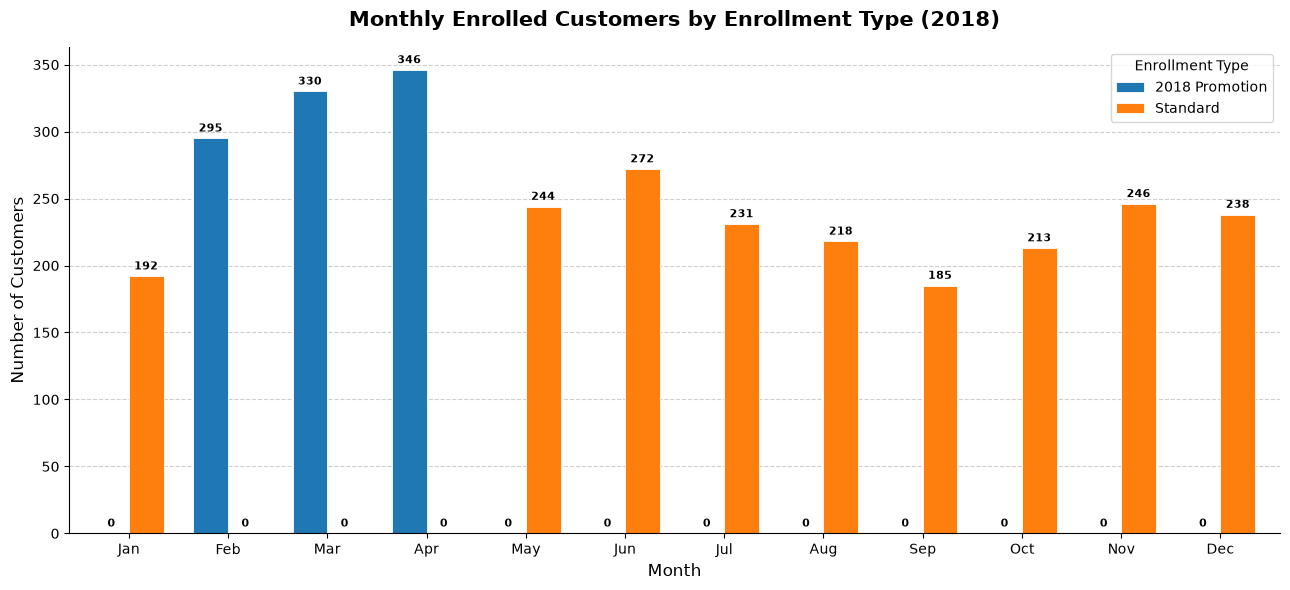

In [200]:
# Bar chart: Monthly enrollments in 2018 by Enrollment Type (Jan–Dec)

import calendar

enrolled_2018 = customer_loyalty[customer_loyalty["Enrollment Year"] == 2018]

# Group by month and enrollment type
monthly_counts = (
    enrolled_2018
    .groupby(["Enrollment Month", "Enrollment Type"])
    .size()
    .reset_index(name="Number of Customers")
)

# Pivot so each Enrollment Type becomes a column
monthly_pivot = monthly_counts.pivot(index="Enrollment Month", columns="Enrollment Type", values="Number of Customers").fillna(0)

# Ensure all 12 months are present
monthly_pivot = monthly_pivot.reindex(range(1, 13), fill_value=0)

# Replace month numbers with abbreviated names
monthly_pivot.index = [calendar.month_abbr[m] for m in monthly_pivot.index]

fig, ax = plt.subplots(figsize=(13, 6))

monthly_pivot.plot(
    kind="bar",
    ax=ax,
    color=["#1f77b4", "#ff7f0e"],
    edgecolor="white",
    linewidth=0.6,
    width=0.7
)

# Add value labels on top of each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%g", fontsize=8, fontweight="bold", padding=3)

ax.set_title("Monthly Enrolled Customers by Enrollment Type (2018)", fontsize=15, fontweight="bold", pad=15)
ax.set_xlabel("Month", fontsize=12)
ax.set_ylabel("Number of Customers", fontsize=12)
ax.set_xticklabels(monthly_pivot.index, rotation=0, fontsize=10)
ax.legend(title="Enrollment Type", fontsize=10, title_fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
ax.yaxis.grid(True, linestyle="--", alpha=0.6)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

The 3 promotion months saw more enrolled customers than the rest of the year. 
The promotion developed desired customer behavior in this sense, attracting more customers.

/tmp/ipykernel_393038/4066738938.py:2: Pandas4Warning: 'and' operations between boolean dtype and str are deprecated and will raise in a future version. Explicitly cast the strings to a boolean dtype before operating instead.
  promo_2018 = customer_loyalty[(customer_loyalty['Enrollment Type']=='2018 Promotion')


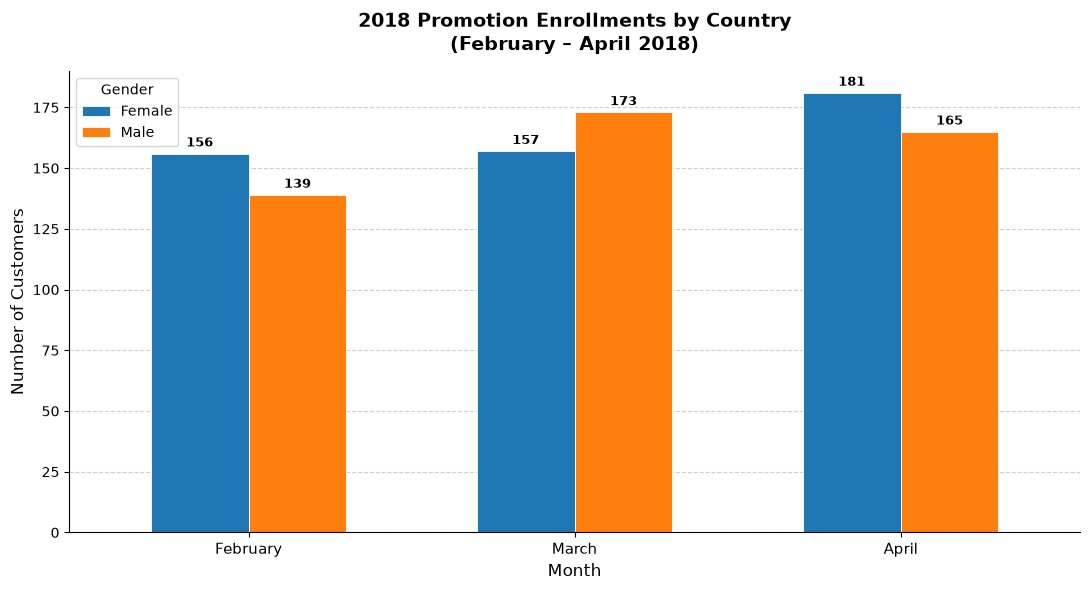

In [201]:
# bar chart showing promotion enrollments per country per month
promo_2018 = customer_loyalty[(customer_loyalty['Enrollment Type']=='2018 Promotion')
& (customer_loyalty['Gender'])]

# group by month and gender
promo_counts = (promo_2018.groupby(['Enrollment Month', 'Gender']).size().reset_index(name='Number of Customers'))

# Pivot: rows = months, columns = countries
promo_pivot = promo_counts.pivot(index="Enrollment Month", columns="Gender", values="Number of Customers").fillna(0)
# Label months properly
month_labels = {2: "February", 3: "March", 4: "April"}
promo_pivot.index = [month_labels[m] for m in promo_pivot.index]
fig, ax = plt.subplots(figsize=(11, 6))
promo_pivot.plot(
    kind="bar",
    ax=ax,
    edgecolor="white",
    linewidth=0.6,
    width=0.6
)
# Value labels on each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%g", fontsize=9, fontweight="bold", padding=3)
ax.set_title("2018 Promotion Enrollments by Country\n(February – April 2018)", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Month", fontsize=12)
ax.set_ylabel("Number of Customers", fontsize=12)
ax.set_xticklabels(promo_pivot.index, rotation=0, fontsize=11)
ax.legend(title="Gender", fontsize=10, title_fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
ax.yaxis.grid(True, linestyle="--", alpha=0.6)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

In [202]:
customer_profile.info()

<class 'pandas.DataFrame'>
RangeIndex: 16737 entries, 0 to 16736
Data columns (total 21 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   Loyalty Number      16737 non-null  int64   
 1   Country             16737 non-null  str     
 2   Province            16737 non-null  str     
 3   City                16737 non-null  str     
 4   Postal Code         16737 non-null  str     
 5   Gender              16737 non-null  str     
 6   Education           16737 non-null  str     
 7   Salary              12499 non-null  float64 
 8   Marital Status      16737 non-null  str     
 9   Loyalty Card        16737 non-null  str     
 10  CLV                 16737 non-null  float64 
 11  Enrollment Type     16737 non-null  str     
 12  Enrollment Year     16737 non-null  int64   
 13  Enrollment Month    16737 non-null  int64   
 14  Cancellation Year   16737 non-null  float64 
 15  Cancellation Month  16737 non-null  float64 
 1

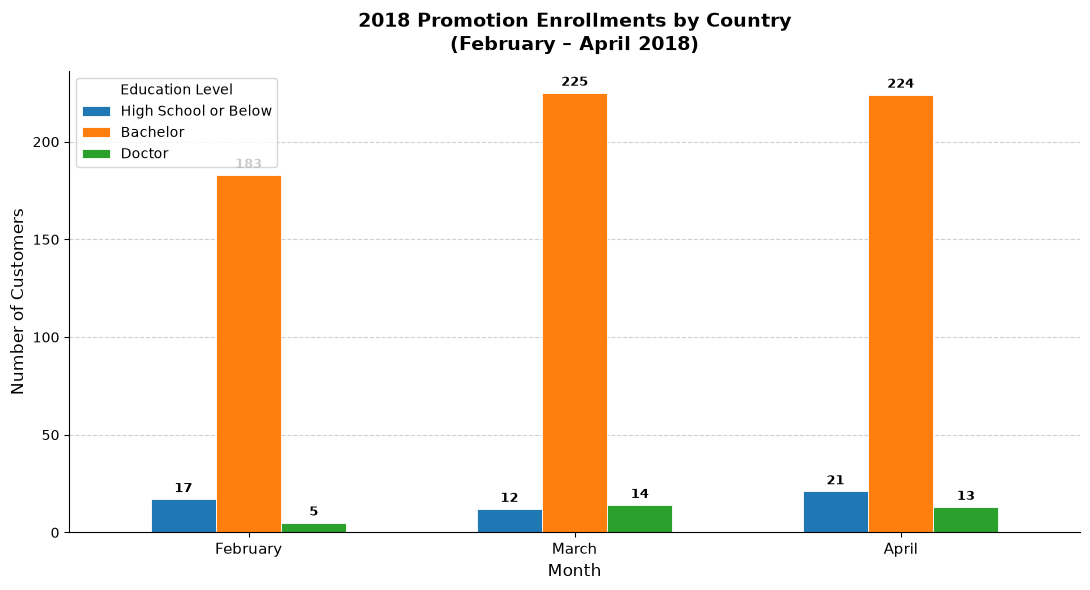

In [203]:
# bar chart showing promotion enrollments per country per month
promo_2018_ed = customer_profile[(customer_profile['Enrollment Type']=='2018 Promotion')
& (customer_profile['EducationLevel'])]

# group by month and education level
promo_counts = (promo_2018_ed.groupby(['Enrollment Month', 'EducationLevel']).size().reset_index(name='Number of Customers'))

# Pivot: rows = months, columns = education level
promo_pivot = promo_counts.pivot(index="Enrollment Month", columns="EducationLevel", values="Number of Customers").fillna(0)
# Label months properly
month_labels = {2: "February", 3: "March", 4: "April"}
promo_pivot.index = [month_labels[m] for m in promo_pivot.index]
fig, ax = plt.subplots(figsize=(11, 6))
promo_pivot.plot(
    kind="bar",
    ax=ax,
    edgecolor="white",
    linewidth=0.6,
    width=0.6
)
# Value labels on each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%g", fontsize=9, fontweight="bold", padding=3)
ax.set_title("2018 Promotion Enrollments by Country\n(February – April 2018)", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Month", fontsize=12)
ax.set_ylabel("Number of Customers", fontsize=12)
ax.set_xticklabels(promo_pivot.index, rotation=0, fontsize=11)

mapping_series = customer_profile.groupby("EducationLevel")["Education"].first()
legend_labels = [mapping_series[col] for col in promo_pivot.columns]

ax.legend(
    labels=legend_labels, title="Education Level", fontsize=10, title_fontsize=10
)

ax.spines[["top", "right"]].set_visible(False)
ax.yaxis.grid(True, linestyle="--", alpha=0.6)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

Customers with degrees had majority of enrollments during the promotion

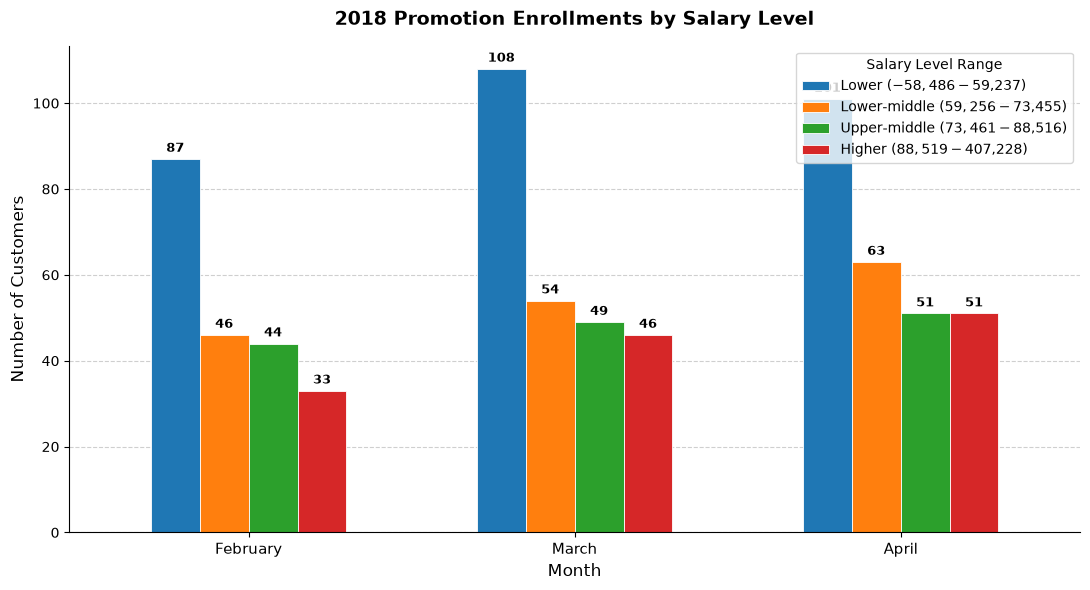

In [204]:
# bar chart showing promotion enrollments per salary band
#promo_2018_salary = customer_profile[(customer_profile['SalaryBand']== 'Upper-middle')]
promo_2018_sal = customer_profile[(customer_profile['Enrollment Type']=='2018 Promotion')]
# group by month and education level
promo_counts = (promo_2018_sal.groupby(['Enrollment Month', 'SalaryBand']).size().reset_index(name='Number of Customers'))

# Pivot: rows = months, columns = salary
promo_pivot = promo_counts.pivot(index="Enrollment Month", columns="SalaryBand", values="Number of Customers").fillna(0)
# Label months properly
month_labels = {2: "February", 3: "March", 4: "April"}
promo_pivot.index = [month_labels[m] for m in promo_pivot.index]
fig, ax = plt.subplots(figsize=(11, 6))
promo_pivot.plot(
    kind="bar",
    ax=ax,
    edgecolor="white",
    linewidth=0.6,
    width=0.6
)
# Value labels on each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%g", fontsize=9, fontweight="bold", padding=3)
ax.set_title("2018 Promotion Enrollments by Salary Level", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Month", fontsize=12)
ax.set_ylabel("Number of Customers", fontsize=12)
ax.set_xticklabels(promo_pivot.index, rotation=0, fontsize=11)

# Dynamic mapping to extract the Min and Max salary value for each band
salary_ranges = customer_profile.groupby("SalaryBand", observed=False)["Salary"].agg(["min", "max"])

# Create descriptive value labels formatted as currency ranges
legend_labels = [
    f"{col} (${salary_ranges.loc[col, 'min']:,.0f} - ${salary_ranges.loc[col, 'max']:,.0f})"
    for col in promo_pivot.columns
]

# Pass these descriptive string labels straight into your legend
ax.legend(
    labels=legend_labels, title="Salary Level Range", fontsize=10, title_fontsize=10
)

ax.spines[["top", "right"]].set_visible(False)
ax.yaxis.grid(True, linestyle="--", alpha=0.6)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

Lower earning customers subscribed significantly more to the flight promotion than middle and higher earners.

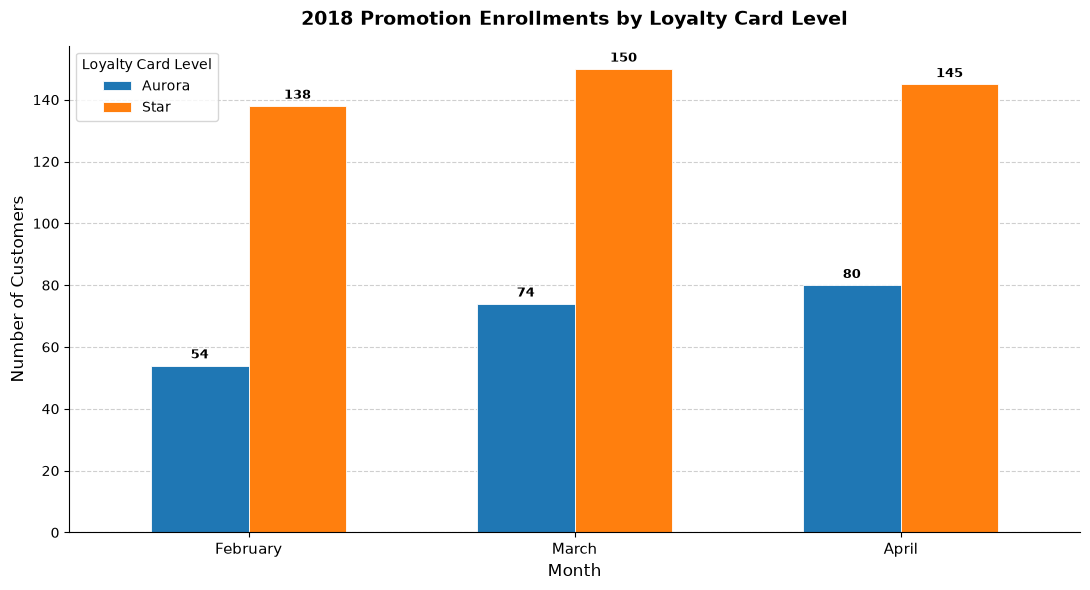

In [205]:
# bar chart showing promotion enrollments per loyalty level
promo_2018_card = customer_profile[(customer_profile['Enrollment Type']=='2018 Promotion')
& (customer_profile['LoyaltyCardLevel'])]

# group by month and loyalty card level
promo_counts = (promo_2018_card.groupby(['Enrollment Month', 'LoyaltyCardLevel']).size().reset_index(name='Number of Customers'))

# Pivot: rows = months, columns = education level
promo_pivot = promo_counts.pivot(index="Enrollment Month", columns="LoyaltyCardLevel", values="Number of Customers").fillna(0)
# Label months properly
month_labels = {2: "February", 3: "March", 4: "April"}
promo_pivot.index = [month_labels[m] for m in promo_pivot.index]
fig, ax = plt.subplots(figsize=(11, 6))
promo_pivot.plot(
    kind="bar",
    ax=ax,
    edgecolor="white",
    linewidth=0.6,
    width=0.6
)
# Value labels on each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%g", fontsize=9, fontweight="bold", padding=3)
ax.set_title("2018 Promotion Enrollments by Loyalty Card Level", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Month", fontsize=12)
ax.set_ylabel("Number of Customers", fontsize=12)
ax.set_xticklabels(promo_pivot.index, rotation=0, fontsize=11)

mapping_series = customer_profile.groupby("LoyaltyCardLevel")["Loyalty Card"].first()
legend_labels = [mapping_series[col] for col in promo_pivot.columns]

ax.legend(
    labels=legend_labels, title="Loyalty Card Level", fontsize=10, title_fontsize=10
)

ax.spines[["top", "right"]].set_visible(False)
ax.yaxis.grid(True, linestyle="--", alpha=0.6)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

Star customer level cards were most subscribed to during this promotion period.

/tmp/ipykernel_393038/3725605372.py:2: Pandas4Warning: 'and' operations between boolean dtype and str are deprecated and will raise in a future version. Explicitly cast the strings to a boolean dtype before operating instead.
  promo_2018_marital = customer_profile[(customer_profile['Enrollment Type']=='2018 Promotion')


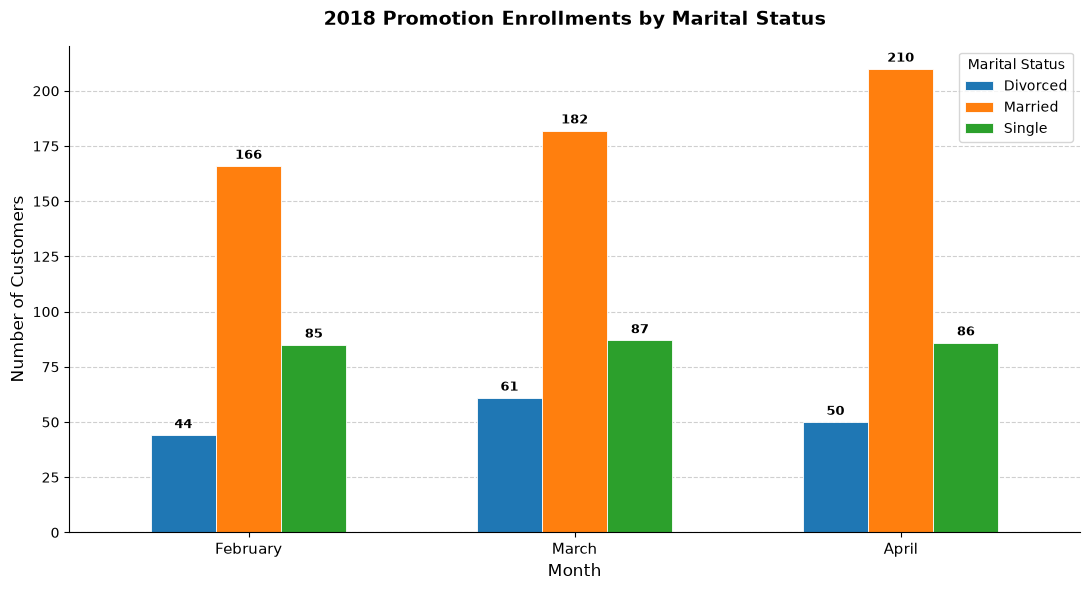

In [208]:
# bar chart showing promotion enrollments per marital status
promo_2018_marital = customer_profile[(customer_profile['Enrollment Type']=='2018 Promotion')
& (customer_profile['Marital Status'])]

# group by month and loyalty card level
promo_counts = (promo_2018_marital.groupby(['Enrollment Month', 'Marital Status']).size().reset_index(name='Number of Customers'))

# Pivot: rows = months, columns = education level
promo_pivot = promo_counts.pivot(index="Enrollment Month", columns="Marital Status", values="Number of Customers").fillna(0)
# Label months properly
month_labels = {2: "February", 3: "March", 4: "April"}
promo_pivot.index = [month_labels[m] for m in promo_pivot.index]
fig, ax = plt.subplots(figsize=(11, 6))
promo_pivot.plot(
    kind="bar",
    ax=ax,
    edgecolor="white",
    linewidth=0.6,
    width=0.6
)
# Value labels on each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%g", fontsize=9, fontweight="bold", padding=3)
ax.set_title("2018 Promotion Enrollments by Marital Status", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Month", fontsize=12)
ax.set_ylabel("Number of Customers", fontsize=12)
ax.set_xticklabels(promo_pivot.index, rotation=0, fontsize=11)
ax.legend(title="Marital Status", fontsize=10, title_fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
ax.yaxis.grid(True, linestyle="--", alpha=0.6)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

Families signed up for the promotion much more than singles and divorced people.

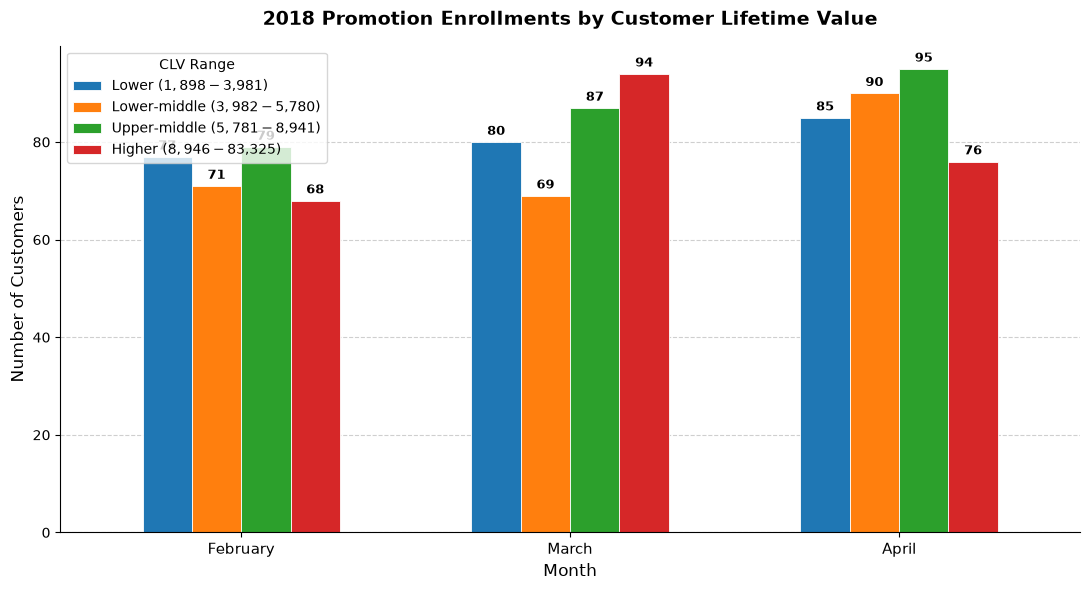

In [214]:
# bar chart showing promotion enrollments per customer lifetime value
promo_2018_card = customer_profile[(customer_profile['Enrollment Type']=='2018 Promotion')]

# group by month and loyalty card level
promo_counts = (promo_2018_card.groupby(['Enrollment Month', 'CLVSegment']).size().reset_index(name='Number of Customers'))

# Pivot: rows = months, columns = education level
promo_pivot = promo_counts.pivot(index="Enrollment Month", columns="CLVSegment", values="Number of Customers").fillna(0)
# Label months properly
month_labels = {2: "February", 3: "March", 4: "April"}
promo_pivot.index = [month_labels[m] for m in promo_pivot.index]
fig, ax = plt.subplots(figsize=(11, 6))
promo_pivot.plot(
    kind="bar",
    ax=ax,
    edgecolor="white",
    linewidth=0.6,
    width=0.6
)
# Value labels on each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%g", fontsize=9, fontweight="bold", padding=3)
ax.set_title("2018 Promotion Enrollments by Customer Lifetime Value", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Month", fontsize=12)
ax.set_ylabel("Number of Customers", fontsize=12)
ax.set_xticklabels(promo_pivot.index, rotation=0, fontsize=11)

# Dynamic mapping to extract the Min and Max salary value for each band
clv_ranges = customer_profile.groupby("CLVSegment", observed=False)["CLV"].agg(["min", "max"])

# Create descriptive value labels formatted as currency ranges
legend_labels = [
    f"{col} (${clv_ranges.loc[col, 'min']:,.0f} - ${clv_ranges.loc[col, 'max']:,.0f})"
    for col in promo_pivot.columns
]

# Pass these descriptive string labels straight into your legend
ax.legend(
    labels=legend_labels, title="CLV Range", fontsize=10, title_fontsize=10
)

ax.spines[["top", "right"]].set_visible(False)
ax.yaxis.grid(True, linestyle="--", alpha=0.6)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()